<a href="https://colab.research.google.com/github/Pris1720/INTELIGENCIA-ARTIFICIAL---TA---GRUPO-5/blob/main/Grupo5_TA_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1INF24 - INTELIGENCIA ARTIFICIAL
## Trabajo Académico Final - Grupo 5
**Tema:** Sistema de Inferencia Difusa Mamdani para la Evaluación Explicable del Riesgo de Deserción en Estudiantes Universitarios de Primer Semestre  
**Integrantes:** Gabriela Lucia Checa Meza, Priscila Murillo Barrientos, Camilo Gomez Casalino, Renzo Arevalo Carles

En este notebook se implementa el sistema de inferencia difusa tipo Mamdani utilizando la librería `scikit-fuzzy` (siguiendo el esquema desarrollado en la Semana 13 del curso) y se ejecutan los experimentos E1 al E8 sobre el dataset de educación superior (`dataset.csv`).

# 1. Preparación y carga de datos
<b>Instalación de scikit-fuzzy</b>:

In [2]:
!pip install -q scikit-fuzzy

In [3]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, fbeta_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42          # semilla de la partición y de los Random Forest
TEST_SIZE = 0.30   # 70% entrenamiento / 30% prueba
BETA = 2           # F2: la sensibilidad pesa el doble que la precisión

DATA_PATH = Path("dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError("No se encontró dataset.csv: colóquelo junto a este notebook.")

#### Carga del dataset y filtrado de casos
Cargamos el archivo `dataset.csv` y excluimos a los estudiantes con estado `Enrolled`, ya que aún siguen cursando y no tienen un resultado final. Definimos nuestra variable objetivo binaria: `y = 1` si abandonó (`Dropout`) y `y = 0` si se graduó (`Graduate`).

In [4]:
pd_original = pd.read_csv(DATA_PATH)
print("Dimensiones del dataset original:", pd_original.shape)
print("Valores nulos:", int(pd_original.isna().sum().sum()))
display(pd_original["Target"].value_counts().to_frame("cantidad"))

pd_modelado = pd_original[pd_original["Target"].isin(["Dropout", "Graduate"])].copy()
pd_modelado["y"] = (pd_modelado["Target"] == "Dropout").astype(int)
print("Estudiantes tras excluir Enrolled:", len(pd_modelado))
print(f"Abandonaron (y=1): {pd_modelado['y'].sum()} ({pd_modelado['y'].mean():.1%})  |  "
      f"Graduados (y=0): {(pd_modelado['y'] == 0).sum()}")

Dimensiones del dataset original: (4424, 35)
Valores nulos: 0


,cantidad
Target,
Graduate,2209
Dropout,1421
Enrolled,794


Estudiantes tras excluir Enrolled: 3630
Abandonaron (y=1): 1421 (39.1%)  |  Graduados (y=0): 2209


#### Cálculo de los índices de entrada
Condensamos las variables del primer semestre en dos indicadores:
- **Rendimiento académico ($a$):** $a = 0.5\,g + 10\,p$ (escala 0–20), donde $g$ es el promedio de notas y $p$ es la proporción de cursos aprobados sobre matriculados (si no tiene cursos matriculados, $p = 0$).
- **Vulnerabilidad económica ($e$):** $e = 0.5\,(1 - T) + 0.3\,D + 0.2\,(1 - B)$ (escala 0–1), donde $T$ indica pensión al día, $D$ si es deudor y $B$ si tiene beca.

In [5]:
def calcular_indices(df):
    out = df.copy()
    matric = out["Curricular units 1st sem (enrolled)"].to_numpy(dtype=float)
    aprob = out["Curricular units 1st sem (approved)"].to_numpy(dtype=float)
    nota = out["Curricular units 1st sem (grade)"].to_numpy(dtype=float)
    # p = aprobados / matriculados (p = 0 si no hay cursos matriculados)
    p = np.divide(aprob, matric, out=np.zeros(len(out)), where=matric != 0)
    out["p_approved"] = np.clip(p, 0, 1)
    out["a_academic"] = 0.5 * nota + 10 * out["p_approved"]
    T = out["Tuition fees up to date"]; D = out["Debtor"]; B = out["Scholarship holder"]
    out["e_economic"] = (0.5 * (1 - T) + 0.3 * D + 0.2 * (1 - B)).clip(0, 1)
    return out

pd_modelado = calcular_indices(pd_modelado)
print("Estudiantes sin cursos matriculados (p = 0):",
      int((pd_modelado["Curricular units 1st sem (enrolled)"] == 0).sum()))
display(pd_modelado[["Target", "y", "p_approved", "a_academic", "e_economic"]].head())
display(pd_modelado[["a_academic", "e_economic"]].describe().round(3))

Estudiantes sin cursos matriculados (p = 0): 152


,Target,y,p_approved,a_academic,e_economic
0,Dropout,1,0.000000,0.000000,0.2
1,Graduate,0,1.000000,17.000000,0.7
2,Dropout,1,0.000000,0.000000,0.7
3,Graduate,0,1.000000,16.714286,0.2
4,Graduate,0,0.833333,14.500000,0.2


,a_academic,e_economic
count,3630.000,3630.000
mean,12.267,0.248
std,6.133,0.257
min,0.000,0.000
25%,10.848,0.200
50%,15.125,0.200
75%,16.500,0.200
max,19.438,1.000


# 2. Fusificación
#### Clase para definir variables lingüísticas

In [6]:
class VariableLinguistica:
    def __init__(self, universo, fp_terminos):
        self.universo = universo   # Universo de discurso
        self.fp = fp_terminos      # Diccionario de Funciones de Pertenencia (FP) de cada termino
                                   # El key es el nombre del termino linguistico.

#### Definición de variables lingüísticas y funciones de pertenencia
Definimos los conjuntos difusos para las dos entradas (`academic` y `economic`) y para la salida (`risk`), usando funciones trapezoidales en los extremos y triangulares en el centro según los rangos establecidos en la Sección 3.3 del informe.

In [7]:
# np.round evita errores de redondeo en los puntos del universo (p. ej., 0.70000000001)
# crea variable linguistica academic (rendimiento académico a, escala 0-20)
academic_univ = np.round(np.linspace(0, 20, 2001), 2)   # universo de discurso discretizado cada 0.01
academic = VariableLinguistica( academic_univ,
                                # trapecio: 0 (inicio), 0 (inicia plateau), 8 (fin del plateau), 10 (fin)
                                {'Bajo'  : fuzz.trapmf(academic_univ, [0, 0, 8, 10]),
                                # triángulo: 9 (inicia a crecer), 12 (pertenencia 1), 15 (fin)
                                 'Medio' : fuzz.trimf(academic_univ,  [9, 12, 15]),
                                 'Alto'  : fuzz.trapmf(academic_univ, [14, 16, 20, 20])} )

# crea variable linguistica economic (vulnerabilidad económica e, escala 0-1)
economic_univ = np.round(np.linspace(0, 1, 1001), 3)    # universo de discurso discretizado cada 0.001
economic = VariableLinguistica( economic_univ,
                                {'Baja'  : fuzz.trapmf(economic_univ, [0, 0, 0.2, 0.4]),
                                 'Media' : fuzz.trimf(economic_univ,  [0.3, 0.5, 0.7]),
                                 'Alta'  : fuzz.trapmf(economic_univ, [0.6, 0.8, 1, 1])} )

# crea variable linguistica risk (riesgo de deserción r, en %)
risk_univ = np.round(np.linspace(0, 100, 1001), 1)      # universo de discurso discretizado cada 0.1 (1001 puntos)
risk = VariableLinguistica( risk_univ,
                            {'Bajo'     : fuzz.trapmf(risk_univ, [0, 0, 20, 40]),
                             'Medio'    : fuzz.trimf(risk_univ,  [20, 40, 60]),
                             'Alto'     : fuzz.trimf(risk_univ,  [50, 70, 90]),
                             'Muy alto' : fuzz.trapmf(risk_univ, [80, 100, 100, 100])} )

In [8]:
risk.fp['Medio'][195:205]   # ejemplo: valores de la FP 'Medio' alrededor de r = 20

array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.005, 0.01 , 0.015,
       0.02 ])

#### Función para plotear funciones de pertenencia de una variable lingüística

In [9]:
def PlotFP (Varling, xlabel='', archivo=None):
    colores = ['r', 'b', 'g', 'y', 'm', 'k']
    icolor = 0
    terminos = []
    for termino in Varling.fp.keys():
        c = colores[icolor]
        plt.plot(Varling.universo, Varling.fp[termino], color=c, linewidth=1.5, label=c)
        terminos.append(termino)
        icolor = (icolor + 1) % 6

    plt.ylabel('Funciones de membresia')
    plt.xlabel(xlabel)
    plt.ylim(0,1.5)
    plt.legend(terminos, loc='upper center', ncol=len(terminos))
    if archivo:
        plt.savefig(OUTPUT_DIR / archivo, dpi=200, bbox_inches='tight')
    plt.show()

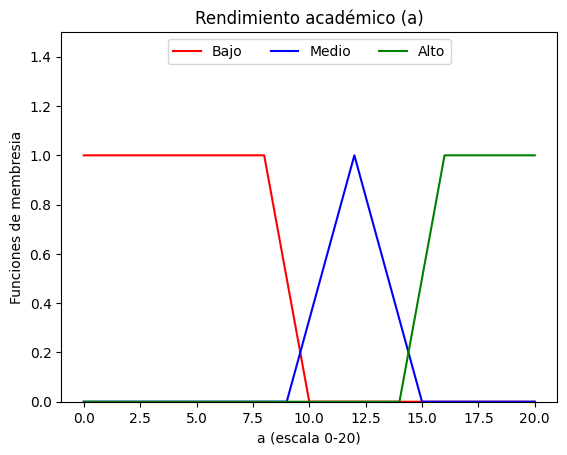

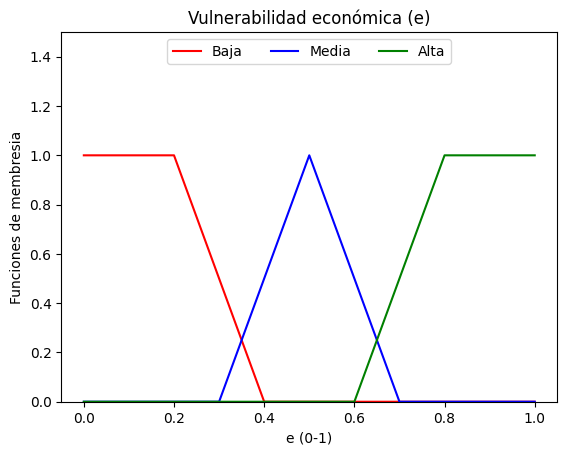

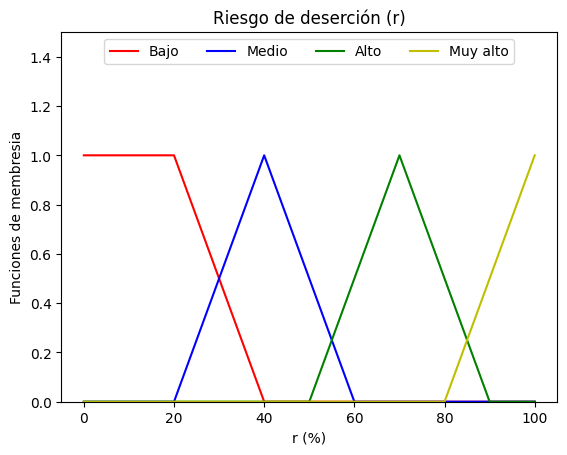

In [10]:
# Muestra las funciones de pertenencia de las variables del presente problema
plt.title('Rendimiento académico (a)')
PlotFP (academic, 'a (escala 0-20)', 'FP_academic.png')

plt.title('Vulnerabilidad económica (e)')
PlotFP (economic, 'e (0-1)', 'FP_economic.png')

plt.title('Riesgo de deserción (r)')
PlotFP (risk, 'r (%)', 'FP_risk.png')

# 3. Base de conocimiento

### Definiendo las reglas difusas
Las reglas se implementan como un diccionario: el key son los términos lingüísticos del antecedente (*a*, *e*) y el valor es el término del consecuente (*r*). Además, se guarda el identificador de cada regla (R1 a R9) para la trazabilidad.

  - R1: Si (*a* es Bajo) y (*e* es Baja) Entonces (*r* es Alto)
  - R2: Si (*a* es Bajo) y (*e* es Media) Entonces (*r* es Alto)
  - R3: Si (*a* es Bajo) y (*e* es Alta) Entonces (*r* es Muy alto)
  - R4: Si (*a* es Medio) y (*e* es Baja) Entonces (*r* es Medio)
  - R5: Si (*a* es Medio) y (*e* es Media) Entonces (*r* es Alto)
  - R6: Si (*a* es Medio) y (*e* es Alta) Entonces (*r* es Muy alto)
  - R7: Si (*a* es Alto) y (*e* es Baja) Entonces (*r* es Bajo)
  - R8: Si (*a* es Alto) y (*e* es Media) Entonces (*r* es Bajo)
  - R9: Si (*a* es Alto) y (*e* es Alta) Entonces (*r* es Alto)

In [11]:
reglas = { ('Bajo','Baja')   : 'Alto',
           ('Bajo','Media')  : 'Alto',
           ('Bajo','Alta')   : 'Muy alto',
           ('Medio','Baja')  : 'Medio',
           ('Medio','Media') : 'Alto',
           ('Medio','Alta')  : 'Muy alto',
           ('Alto','Baja')   : 'Bajo',
           ('Alto','Media')  : 'Bajo',
           ('Alto','Alta')   : 'Alto',
         }

# identificador de cada regla (R1..R9) en el mismo orden, para la trazabilidad
id_regla = { ant_terms: f'R{i}' for i, ant_terms in enumerate(reglas.keys(), start=1) }
id_regla

{('Bajo', 'Baja'): 'R1',
 ('Bajo', 'Media'): 'R2',
 ('Bajo', 'Alta'): 'R3',
 ('Medio', 'Baja'): 'R4',
 ('Medio', 'Media'): 'R5',
 ('Medio', 'Alta'): 'R6',
 ('Alto', 'Baja'): 'R7',
 ('Alto', 'Media'): 'R8',
 ('Alto', 'Alta'): 'R9'}

Podemos visualizar las reglas en forma de matriz (filas: rendimiento *a*; columnas: vulnerabilidad *e*):

In [12]:
academic_lst = [clave[0] for clave in reglas.keys()]   # 'Bajo', 'Bajo', 'Bajo', 'Medio', ...
economic_lst = [clave[1] for clave in reglas.keys()]   # 'Baja', 'Media', 'Alta', ...
risk_lst = [f'{reglas[clave]} ({id_regla[clave]})' for clave in reglas.keys()]   # 'Alto (R1)', ...

df = pd.DataFrame({
    'academic': academic_lst,
    'economic': economic_lst,
    'risk': risk_lst
})

matriz_reglas = df.pivot(index='academic', columns='economic', values='risk')
matriz_reglas = matriz_reglas.reindex(index=['Bajo', 'Medio', 'Alto'], columns=['Baja', 'Media', 'Alta'])
matriz_reglas

economic,Baja,Media,Alta
academic,,,
Bajo,Alto (R1),Alto (R2),Muy alto (R3)
Medio,Medio (R4),Alto (R5),Muy alto (R6)
Alto,Bajo (R7),Bajo (R8),Alto (R9)


In [13]:
reglas[('Bajo','Alta')]

'Muy alto'

# 4. Motor de inferencia Mamdani
Implementamos la función `InferenciaMamdani` siguiendo la misma estructura de la clase (Semana 13):
- **Conectivo AND:** mínimo (`np.fmin`)
- **Implicación:** corte-α con mínimo (`np.fmin`)
- **Agregación:** máximo (`np.fmax`)
- **Defusificación:** centroide (`fuzz.defuzz(..., 'centroid')`)

Para adaptarla a nuestro proyecto, agregamos tres opciones adicionales:
1. Retornar la lista de reglas activadas y la **regla dominante** (la de mayor grado de activación) para identificar la causa del riesgo de cada estudiante.
2. Un parámetro `graficar` (desactivado por defecto) para evitar generar miles de gráficos al evaluar los 3,630 registros del dataset.
3. Los parámetros `conectivo` y `defusificacion` para poder probar las variantes del experimento de sensibilidad (E4) sin duplicar código.

In [14]:
def InferenciaMamdani( ant1_in, ant2_in, Ant1, Ant2, Con, reglas, graficar=False,
                       conectivo='min', defusificacion='centroid'):

    # Calcula la implicacion en reglas activadas
    fp_agregada = np.zeros_like(Con.universo)   # array para agregar todas las FPs de salida implicadas
    activadas = []                              # (id de regla, nivel de activacion) para la trazabilidad
    for ant_terms in reglas.keys():    # itera las reglas
        # fuzz.interp_membership obtiene el grado de pertenencia de un valor crisp en un termino linguistico
        alpha1 = fuzz.interp_membership( Ant1.universo, Ant1.fp[ant_terms[0]], ant1_in ) # nivel de activacion de antecedente 1 (a)
        alpha2 = fuzz.interp_membership( Ant2.universo, Ant2.fp[ant_terms[1]], ant2_in ) # nivel de activacion de antecedente 2 (e)
        if conectivo == 'min':
            alpha_min = np.fmin( alpha1, alpha2 )  # minimo de activacion de los dos antecedentes (conectivo AND)
        else:
            alpha_min = alpha1 * alpha2            # variante E4: producto

        if alpha_min > 0:   # Procesa la implicacion solo si la regla esta activada (alpha_min >0)
            con_term = reglas[ant_terms]  # obtiene el termino consecuente de la regla
            # Implicacion Mamdani: alpha corte de la FP del termino consecuente al nivel alpha_min
            if conectivo == 'min':
                fp_con_activ = np.fmin( alpha_min, Con.fp[ con_term ] )
            else:
                fp_con_activ = alpha_min * Con.fp[ con_term ]   # variante E4: implicacion producto

            # Agrega/agrupa la FP con lo ya agregado hasta ahora (agregacion Max)
            fp_agregada = np.fmax(fp_agregada, fp_con_activ)
            regla = id_regla.get(ant_terms, '-'.join(ant_terms))
            activadas.append((regla, float(alpha_min)))

            if graficar:   # Plotea la FP del termino del consecuente implicado
                plt.plot(Con.universo, Con.fp[con_term], '--', color='gray', linewidth=1)
                plt.plot(Con.universo, fp_con_activ, color='g', linewidth=1.5)
                plt.ylabel('Funcion de pertenencia')
                plt.ylim(0,1.5)
                plt.title(f'FP activada del consecuente para regla {regla}: a={ant_terms[0]}, '
                          f'e={ant_terms[1]}, r={con_term} (alpha={alpha_min:.3f})')
                plt.show()

    if not activadas:   # ningun termino cubre la entrada (no ocurre con estas FPs)
        return {'riesgo': np.nan, 'reglas_activadas': '', 'regla_dominante': 'SIN_REGLA', 'n_reglas': 0}

    # Defusificacion (por defecto, centroide)
    result_con = fuzz.defuzz(Con.universo, fp_agregada, defusificacion)

    if graficar:   # plotea la FP agregada del consecuente
        plt.plot(Con.universo, fp_agregada, color='g', linewidth=1.5)
        plt.axvline(result_con, color='k', linestyle='--', label=f'{defusificacion}: r = {result_con:.2f} %')
        plt.ylabel('Funcion de pertenencia')
        plt.ylim(0,1.5)
        plt.legend()
        plt.title('Agregacion de todas las FPs activadas')
        plt.show()

    return {'riesgo': float(result_con),
            'reglas_activadas': ';'.join(f'{r}:{w:.4f}' for r, w in activadas),
            'regla_dominante': max(activadas, key=lambda t: t[1])[0],
            'n_reglas': len(activadas)}

In [15]:
fuzz.interp_membership( academic.universo, academic.fp['Medio'], 13.5 )

np.float64(0.5)

In [16]:
np.fmin( 0.5, [0.2, 0.4, 0.6, 0.8, 1.0] )

array([0.2, 0.4, 0.5, 0.5, 0.5])

## Probando el sistema
Los dos primeros parámetros son los valores crisp de las entradas (*a* y *e*); el tercero y cuarto, las variables lingüísticas del antecedente (`academic` y `economic`); el quinto, la variable de salida (`risk`); y el sexto, la base de reglas. Ejemplo: un estudiante con *a* = 11.5 y *e* = 0.45.

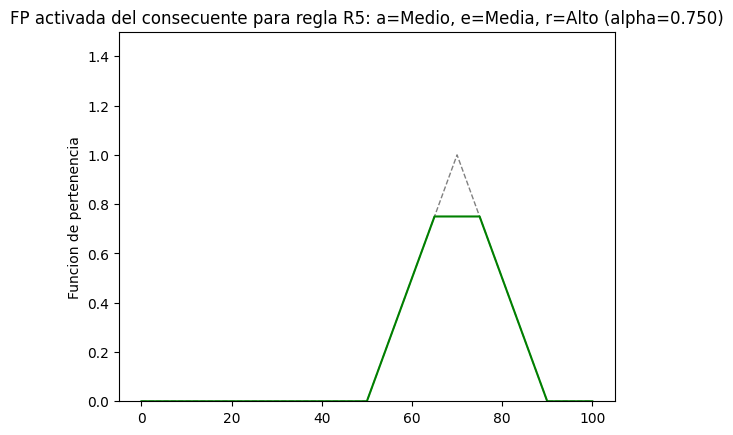

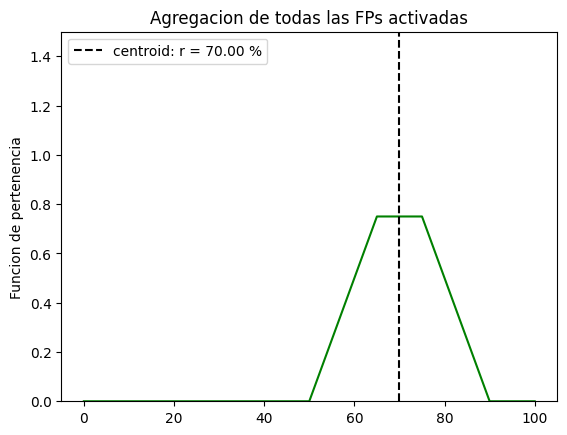

{'riesgo': 69.99999999999999,
 'reglas_activadas': 'R5:0.7500',
 'regla_dominante': 'R5',
 'n_reglas': 1}

In [17]:
InferenciaMamdani( 11.5, 0.45, academic, economic, risk, reglas, graficar=True )

#### Funciones para evaluación masiva e interpretación
Creamos tres funciones de apoyo para aplicar el sistema a todo el dataset:
- `evaluar`: calcula el riesgo $r$ y las reglas activadas para todos los estudiantes de una tabla.
- `etiqueta_riesgo`: devuelve el nivel de riesgo (`Bajo`, `Medio`, `Alto` o `Muy alto`) con mayor grado de pertenencia.
- `causa_regla`: traduce la regla dominante en una causa clara (`académica`, `económica` o `combinada`) para orientar al tutor.

In [18]:
def evaluar(df, Ant1=None, Ant2=None, Con=None, **kw):
    """Riesgo Mamdani (en %) y trazabilidad para cada fila de df."""
    Ant1 = Ant1 or academic; Ant2 = Ant2 or economic; Con = Con or risk
    filas = [InferenciaMamdani(a, e, Ant1, Ant2, Con, reglas, **kw)
             for a, e in zip(df["a_academic"], df["e_economic"])]
    return pd.DataFrame(filas, index=df.index)

def etiqueta_riesgo(r):
    grados = {t: float(fuzz.interp_membership(risk.universo, risk.fp[t], r)) for t in risk.fp}
    return max(grados, key=grados.get)

def causa_regla(regla):
    for (ta, te), rid in id_regla.items():
        if rid == regla:
            acad, econ = ta != 'Alto', te != 'Baja'
            return {(True, True): 'combinada', (True, False): 'académica',
                    (False, True): 'económica', (False, False): 'ninguna (perfil favorable)'}[(acad, econ)]
    return 'sin regla'

# Inferencia para los 3630 estudiantes (el sistema no se entrena: no depende de la partición)
t0 = time.perf_counter()
pd_modelado = pd_modelado.join(evaluar(pd_modelado))
print(f"Inferencia de {len(pd_modelado)} estudiantes en {time.perf_counter() - t0:.1f} s")
print(f"Rango de r: [{pd_modelado['riesgo'].min():.2f}, {pd_modelado['riesgo'].max():.2f}] %   "
      f"| riesgos nulos: {pd_modelado['riesgo'].isna().sum()}")
pd_modelado["etiqueta_riesgo"] = pd_modelado["riesgo"].apply(etiqueta_riesgo)
pd_modelado["causa"] = pd_modelado["regla_dominante"].apply(causa_regla)
display(pd_modelado[["a_academic", "e_economic", "riesgo", "etiqueta_riesgo",
                     "reglas_activadas", "regla_dominante", "causa", "Target"]].head())

Inferencia de 3630 estudiantes en 12.7 s
Rango de r: [15.56, 93.33] %   | riesgos nulos: 0


,a_academic,e_economic,riesgo,etiqueta_riesgo,reglas_activadas,regla_dominante,causa,Target
0,0.000000,0.2,70.000000,Alto,R1:1.0000,R1,académica,Dropout
1,17.000000,0.7,70.000000,Alto,R9:0.5000,R9,económica,Graduate
2,0.000000,0.7,92.222222,Muy alto,R3:0.5000,R3,combinada,Dropout
3,16.714286,0.2,15.555556,Bajo,R7:1.0000,R7,ninguna (perfil favorable),Graduate
4,14.500000,0.2,26.529967,Bajo,R4:0.1667;R7:0.2500,R7,ninguna (perfil favorable),Graduate


# 5. Prueba de trazabilidad (Experimento E6)
En esta sección ejecutamos la inferencia paso a paso (mostrando las gráficas de implicación y agregación, igual que en el codigo de clase) sobre tres estudiantes reales del conjunto de prueba (`pd_test`):

- **Caso 1 - Riesgo bajo (ID 3):** estudiante con buen rendimiento académico y baja vulnerabilidad económica.
- **Caso 2 - Riesgo medio (ID 65):** estudiante con perfil intermedio y alerta moderada.
- **Caso 3 - Zona gris (ID 393):** estudiante con valores intermedios donde se activan múltiples reglas en simultáneo.

*Nota:* El `ID` corresponde al índice original del registro en `dataset.csv`. En la Sección 6.1 se valida automáticamente que los tres casos pertenecen a la partición de prueba y son los primeros registros en cumplir cada perfil.

Caso 1: riesgo bajo (ID 3, estado real: Graduate)
Entradas: a = 16.71  (nota g = 13.43, p = 1.00)   |   e = 0.20
1) Fusificación  a: {'Bajo': 0.0, 'Medio': 0.0, 'Alto': 1.0} | e: {'Baja': 1.0, 'Media': 0.0, 'Alta': 0.0}


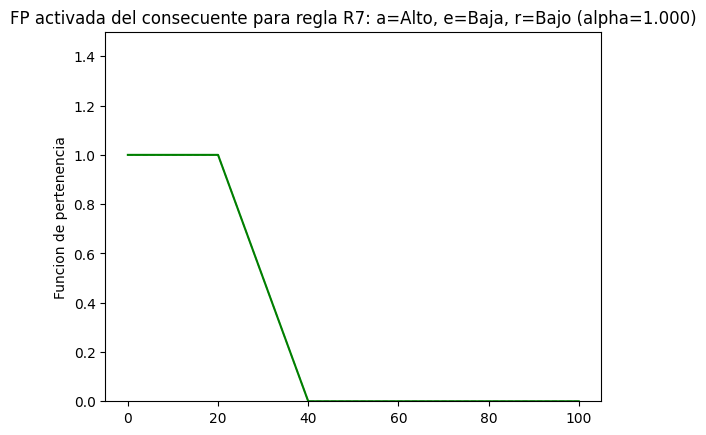

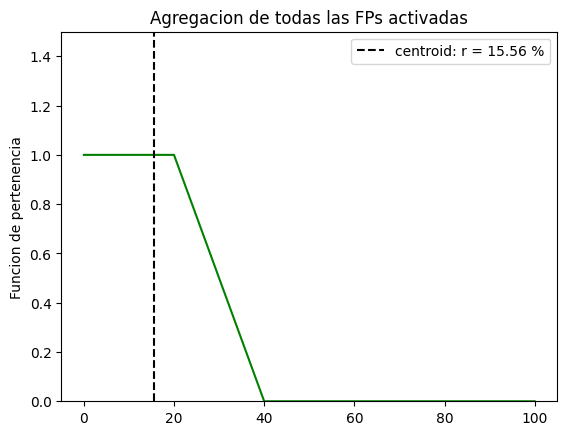

2) Reglas activadas (alpha): R7:1.0000
3) Riesgo r = 15.56 %  -> etiqueta 'Bajo'
4) Regla dominante: R7  -> causa ninguna (perfil favorable)
Caso 2: riesgo medio (ID 65, estado real: Dropout)
Entradas: a = 13.09  (nota g = 11.90, p = 0.71)   |   e = 0.20
1) Fusificación  a: {'Bajo': 0.0, 'Medio': 0.636, 'Alto': 0.0} | e: {'Baja': 1.0, 'Media': 0.0, 'Alta': 0.0}


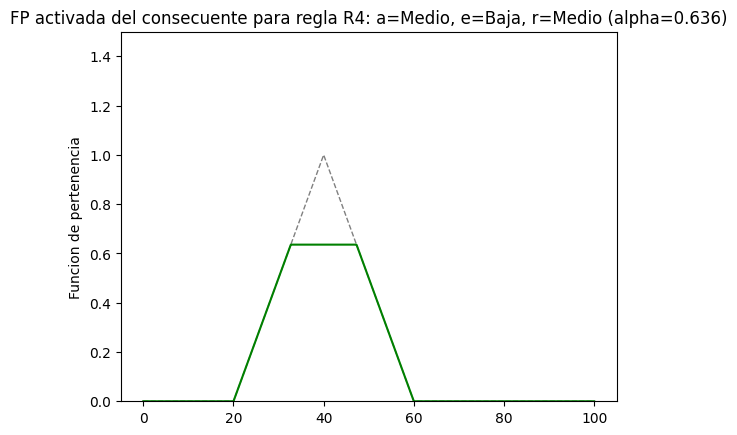

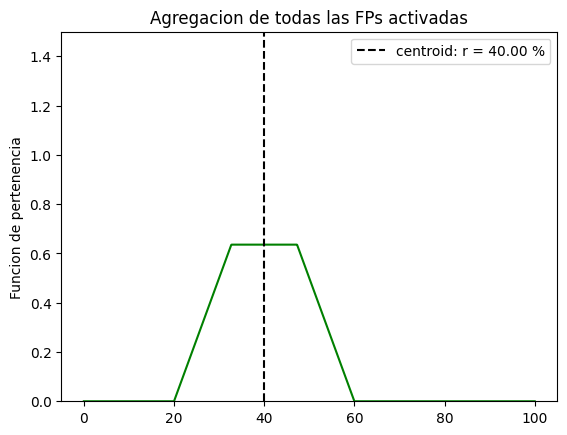

2) Reglas activadas (alpha): R4:0.6357
3) Riesgo r = 40.00 %  -> etiqueta 'Medio'
4) Regla dominante: R4  -> causa académica
Caso 3: zona gris (ID 393, estado real: Dropout)
Entradas: a = 9.25  (nota g = 10.50, p = 0.40)   |   e = 0.70
1) Fusificación  a: {'Bajo': 0.375, 'Medio': 0.083, 'Alto': 0.0} | e: {'Baja': 0.0, 'Media': 0.0, 'Alta': 0.5}


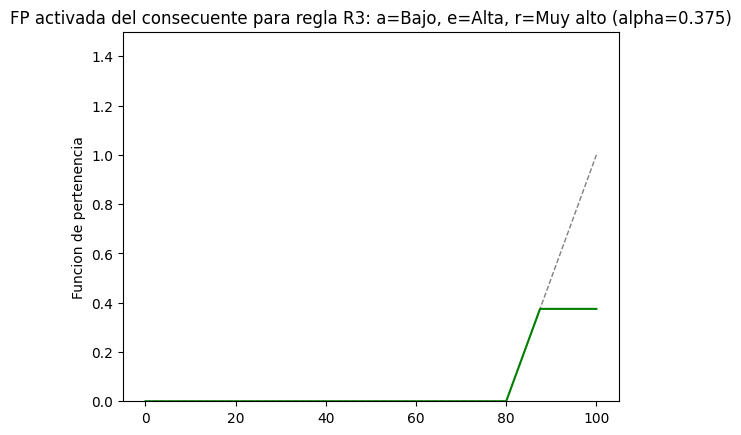

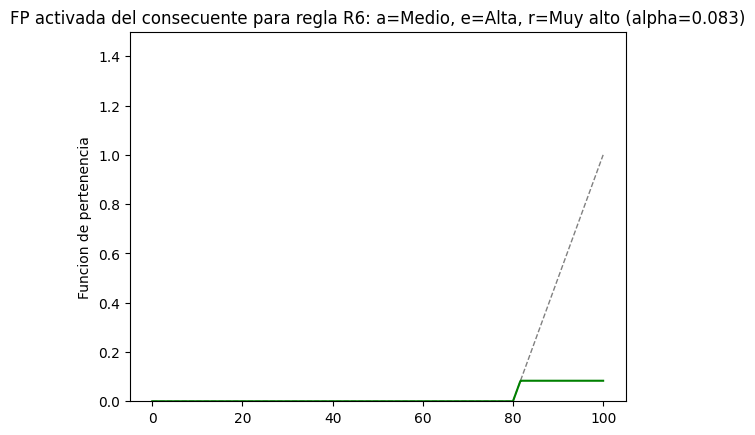

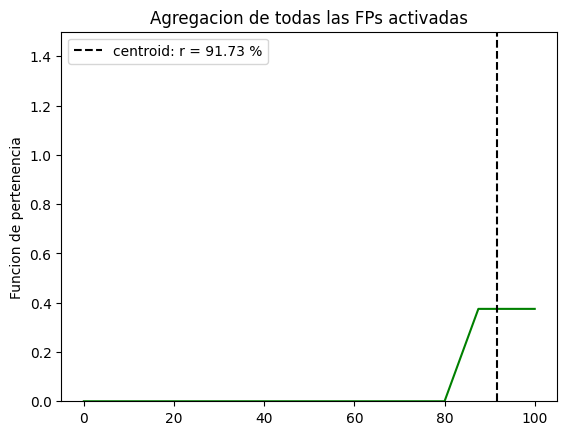

2) Reglas activadas (alpha): R3:0.3750;R6:0.0833
3) Riesgo r = 91.73 %  -> etiqueta 'Muy alto'
4) Regla dominante: R3  -> causa combinada


,perfil,ID,a,e,reglas_activadas,riesgo_%,etiqueta,regla_dominante,causa,estado_real
0,Caso 1: riesgo bajo,3,16.71,0.2,R7:1.0000,15.6,Bajo,R7,ninguna (perfil favorable),Graduate
1,Caso 2: riesgo medio,65,13.09,0.2,R4:0.6357,40.0,Medio,R4,académica,Dropout
2,Caso 3: zona gris,393,9.25,0.7,R3:0.3750;R6:0.0833,91.7,Muy alto,R3,combinada,Dropout


In [19]:
casos_E6 = {'Caso 1: riesgo bajo': 3, 'Caso 2: riesgo medio': 65, 'Caso 3: zona gris': 393}

filas_e6 = []
for perfil, idx in casos_E6.items():
    fila = pd_modelado.loc[idx]
    a_in, e_in = fila['a_academic'], fila['e_economic']
    print('=' * 90)
    print(f"{perfil} (ID {idx}, estado real: {fila['Target']})")
    print(f"Entradas: a = {a_in:.2f}  (nota g = {fila['Curricular units 1st sem (grade)']:.2f}, "
          f"p = {fila['p_approved']:.2f})   |   e = {e_in:.2f}")
    # 1) Fusificacion
    print('1) Fusificación  a:', {t: round(float(fuzz.interp_membership(academic.universo, fp, a_in)), 3)
                                  for t, fp in academic.fp.items()},
          '| e:', {t: round(float(fuzz.interp_membership(economic.universo, fp, e_in)), 3)
                   for t, fp in economic.fp.items()})
    # 2) a 4) Implicacion, agregacion y defusificacion (con graficas)
    res = InferenciaMamdani(a_in, e_in, academic, economic, risk, reglas, graficar=True)
    print(f"2) Reglas activadas (alpha): {res['reglas_activadas']}")
    print(f"3) Riesgo r = {res['riesgo']:.2f} %  -> etiqueta '{etiqueta_riesgo(res['riesgo'])}'")
    print(f"4) Regla dominante: {res['regla_dominante']}  -> causa {causa_regla(res['regla_dominante'])}")
    filas_e6.append({'perfil': perfil, 'ID': idx, 'a': round(a_in, 2), 'e': round(e_in, 2),
                     'reglas_activadas': res['reglas_activadas'], 'riesgo_%': round(res['riesgo'], 1),
                     'etiqueta': etiqueta_riesgo(res['riesgo']), 'regla_dominante': res['regla_dominante'],
                     'causa': causa_regla(res['regla_dominante']), 'estado_real': fila['Target']})

df_e6 = pd.DataFrame(filas_e6)
df_e6.to_csv(OUTPUT_DIR / 'E6_casos_explicabilidad.csv', index=False)
df_e6

#### Verificación global de etiquetas y causas
Revisamos dos aspectos sobre los 3,630 estudiantes: qué porcentaje abandona realmente en cada nivel de riesgo asignado por el sistema, y qué causa (académica, económica o combinada) predomina entre quienes desertaron.

In [20]:
orden_r = ['Bajo', 'Medio', 'Alto', 'Muy alto']
tabla_etiquetas = (pd_modelado.groupby('etiqueta_riesgo')['y'].agg(['size', 'mean'])
                   .reindex(orden_r).rename(columns={'size': 'n', 'mean': 'tasa_abandono'}))
tabla_etiquetas['tasa_abandono'] = (100 * tabla_etiquetas['tasa_abandono']).round(1)
print('% de abandono real según la etiqueta de riesgo (3630 estudiantes):')
display(tabla_etiquetas)

print('Causa según la regla dominante, entre quienes abandonaron (%):')
display((100 * pd_modelado.loc[pd_modelado['y'] == 1, 'causa'].value_counts(normalize=True)).round(1).to_frame('%'))

% de abandono real según la etiqueta de riesgo (3630 estudiantes):


,n,tasa_abandono
etiqueta_riesgo,,
Bajo,2037,9.4
Medio,512,50.4
Alto,694,85.3
Muy alto,387,98.2


Causa según la regla dominante, entre quienes abandonaron (%):


,%
causa,
académica,49.8
combinada,32.9
ninguna (perfil favorable),12.2
económica,5.1


# 6. Evaluación experimental (E1 a E8)
### 6.1 Partición estratificada 70/30 (`random_state = 42`)

In [21]:
pd_train, pd_test = train_test_split(pd_modelado, test_size=TEST_SIZE, random_state=SEED,
                                     stratify=pd_modelado['y'])
pd_train, pd_test = pd_train.sort_index(), pd_test.sort_index()
print(f"Entrenamiento: {len(pd_train)}  |  Prueba: {len(pd_test)}")
print(f"% abandono  entrenamiento: {pd_train['y'].mean():.3f}  |  prueba: {pd_test['y'].mean():.3f}")

# Comprobación de los casos de E6: pertenecen a prueba y son los primeros que cumplen cada criterio
assert set(casos_E6.values()) <= set(pd_test.index)
zona_gris_test = (pd_test['a_academic'].between(9, 15) & pd_test['e_economic'].between(0.3, 0.7))
criterios = {'Caso 1: riesgo bajo': (pd_test['riesgo'] < 20) & (pd_test['y'] == 0),
             'Caso 2: riesgo medio': pd_test['riesgo'].between(35, 55),
             'Caso 3: zona gris': zona_gris_test & (pd_test['n_reglas'] >= 2) & (pd_test['y'] == 1)}
for perfil, m in criterios.items():
    assert pd_test.index[m][0] == casos_E6[perfil], perfil
print('Casos de E6 verificados:', casos_E6)

Entrenamiento: 2541  |  Prueba: 1089
% abandono  entrenamiento: 0.392  |  prueba: 0.391
Casos de E6 verificados: {'Caso 1: riesgo bajo': 3, 'Caso 2: riesgo medio': 65, 'Caso 3: zona gris': 393}


#### Comprobación de la matriz de reglas con datos de entrenamiento
Agrupamos a los estudiantes de entrenamiento según su término dominante en $a$ y $e$, y calculamos el porcentaje real de deserción en cada celda de la matriz $3 \times 3$ para confirmar que las reglas reflejan el comportamiento de los datos.

In [22]:
def termino_dominante(x, Var):
    grados = {t: float(fuzz.interp_membership(Var.universo, fp, x)) for t, fp in Var.fp.items()}
    return max(grados, key=grados.get)

celdas = pd_train.assign(termino_a=[termino_dominante(v, academic) for v in pd_train['a_academic']],
                         termino_e=[termino_dominante(v, economic) for v in pd_train['e_economic']])
tasa_celda = (100 * celdas.pivot_table(index='termino_a', columns='termino_e', values='y', aggfunc='mean')
              .reindex(index=['Bajo', 'Medio', 'Alto'], columns=['Baja', 'Media', 'Alta'])).round(1)
print('% de abandono en entrenamiento por celda (filas a, columnas e):')
display(tasa_celda)
tasa_celda.to_csv(OUTPUT_DIR / 'tasas_abandono_por_regla.csv')

% de abandono en entrenamiento por celda (filas a, columnas e):


termino_e,Baja,Media,Alta
termino_a,,,
Bajo,87.2,96.0,98.8
Medio,51.0,80.0,97.1
Alto,9.4,30.0,76.9


#### Calibración del umbral $\tau$ y métricas de evaluación
Para convertir el riesgo continuo en una alerta binaria, buscamos el umbral $\tau$ que maximiza el **$F_2$-Score** usando únicamente los datos de entrenamiento (priorizando detectar a quienes abandonan). Luego evaluamos todos los modelos en el conjunto de prueba.

In [23]:
def best_threshold(y, scores):
    candidatos = np.unique(np.r_[0.0, scores, 1.0 + 1e-12])
    vals = np.array([fbeta_score(y, scores >= t, beta=BETA, zero_division=0) for t in candidatos])
    tau = float(max(t for t, v in zip(candidatos, vals) if np.isclose(v, vals.max())))
    return tau, float(vals.max()), candidatos, vals

def metricas(y_tr, s_tr, y_te, s_te):
    tau, f2_tr, _, _ = best_threshold(y_tr, s_tr)
    pred = (s_te >= tau).astype(int)
    return {'tau': tau, 'F2_train': f2_tr,
            'exactitud': accuracy_score(y_te, pred), 'sensibilidad': recall_score(y_te, pred, zero_division=0),
            'precision': precision_score(y_te, pred, zero_division=0),
            'F2': fbeta_score(y_te, pred, beta=BETA, zero_division=0), 'AUC': roc_auc_score(y_te, s_te)}

RF_PARAMS = dict(n_estimators=500, class_weight='balanced', min_samples_leaf=2, n_jobs=-1)
COLS_RF2 = ['a_academic', 'e_economic']
COLS_RF6 = ['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
            'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
            'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']

### 6.2 E1 — Sistema difuso frente a RF-2 y RF-6 (prueba)

,tau,F2_train,exactitud,sensibilidad,precision,F2,AUC
Mamdani,0.191,0.845,0.815,0.906,0.706,0.857,0.910
RF-2,0.269,0.917,0.776,0.908,0.654,0.843,0.914
RF-6,0.292,0.925,0.800,0.880,0.692,0.835,0.915


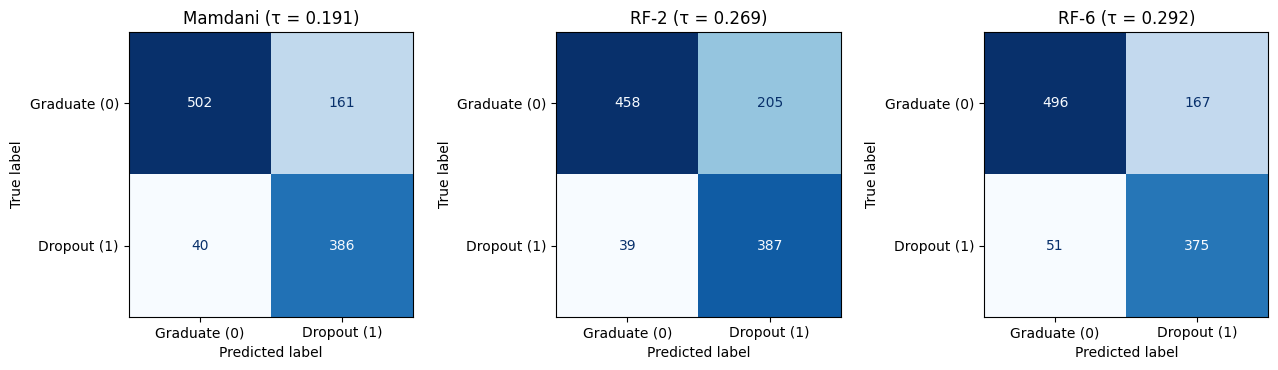

In [24]:
y_tr, y_te = pd_train['y'].to_numpy(), pd_test['y'].to_numpy()
scores = {'Mamdani': (pd_train['riesgo'].to_numpy() / 100, pd_test['riesgo'].to_numpy() / 100)}
for nombre, cols in [('RF-2', COLS_RF2), ('RF-6', COLS_RF6)]:
    rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(pd_train[cols], y_tr)
    scores[nombre] = (rf.predict_proba(pd_train[cols])[:, 1], rf.predict_proba(pd_test[cols])[:, 1])

e1 = pd.DataFrame({m: metricas(y_tr, s_tr, y_te, s_te) for m, (s_tr, s_te) in scores.items()}).T
e1.to_csv(OUTPUT_DIR / 'E1_metricas_test.csv')
display(e1.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (m, (s_tr, s_te)) in zip(axes, scores.items()):
    pred = (s_te >= e1.loc[m, 'tau']).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0, 1]),
                           display_labels=['Graduate (0)', 'Dropout (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{m} (τ = {e1.loc[m, "tau"]:.3f})')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'E1_matrices_confusion.png', dpi=200); plt.show()

### 6.3 E2 — Curvas de F2 frente a τ (entrenamiento) y curvas ROC (prueba)

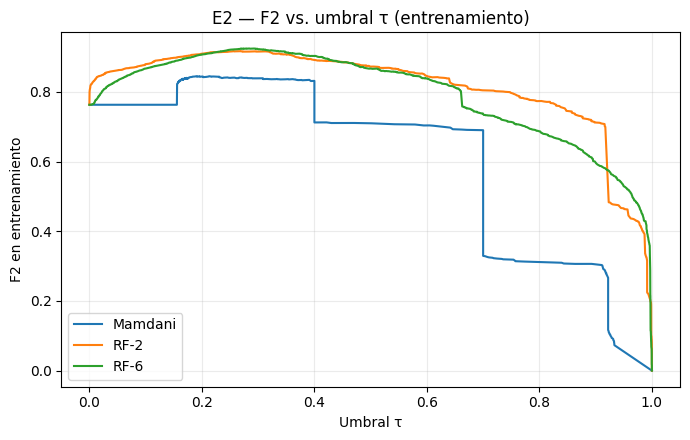

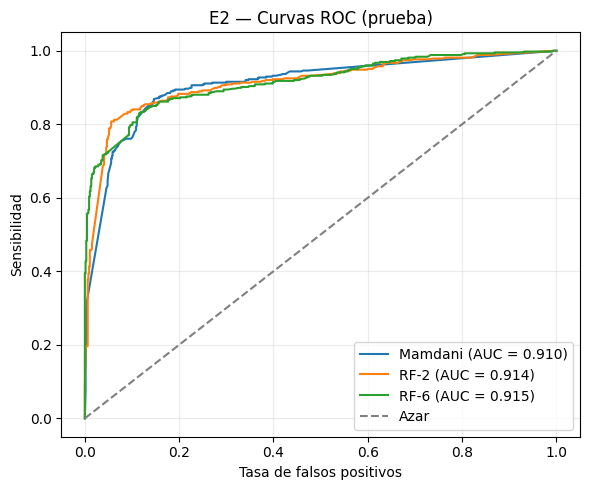

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for m, (s_tr, _) in scores.items():
    _, _, cand, vals = best_threshold(y_tr, s_tr)
    ax.plot(cand, vals, label=m)
ax.set(xlabel='Umbral τ', ylabel='F2 en entrenamiento', title='E2 — F2 vs. umbral τ (entrenamiento)')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'E2_F2_vs_tau.png', dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for m, (_, s_te) in scores.items():
    fpr, tpr, _ = roc_curve(y_te, s_te)
    ax.plot(fpr, tpr, label=f'{m} (AUC = {roc_auc_score(y_te, s_te):.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Azar')
ax.set(xlabel='Tasa de falsos positivos', ylabel='Sensibilidad', title='E2 — Curvas ROC (prueba)')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'E2_ROC.png', dpi=200); plt.show()

### 6.4 E3 - Ablación: aporte de cada variable por separado
Evaluamos qué pasa si el sistema difuso usa únicamente el rendimiento académico ($a$) o únicamente la vulnerabilidad económica ($e$) con 3 reglas simples, frente al sistema completo ($a + e$) de 9 reglas.

In [26]:
def InferenciaMamdani1(x_in, Ant, Con, reglas1):
    """Mamdani con un solo antecedente (para la ablacion E3)."""
    fp_agregada = np.zeros_like(Con.universo)
    for termino, con_term in reglas1.items():
        alpha = fuzz.interp_membership(Ant.universo, Ant.fp[termino], x_in)
        if alpha > 0:
            fp_agregada = np.fmax(fp_agregada, np.fmin(alpha, Con.fp[con_term]))
    return fuzz.defuzz(Con.universo, fp_agregada, 'centroid')

reglas_solo_a = {'Bajo': 'Alto', 'Medio': 'Medio', 'Alto': 'Bajo'}
reglas_solo_e = {'Baja': 'Bajo', 'Media': 'Medio', 'Alta': 'Muy alto'}
r_solo_a = pd.Series([InferenciaMamdani1(a, academic, risk, reglas_solo_a) for a in pd_modelado['a_academic']],
                     index=pd_modelado.index) / 100
r_solo_e = pd.Series([InferenciaMamdani1(e, economic, risk, reglas_solo_e) for e in pd_modelado['e_economic']],
                     index=pd_modelado.index) / 100
r_base = pd_modelado['riesgo'] / 100

e3 = pd.DataFrame({nombre: metricas(y_tr, r.loc[pd_train.index].to_numpy(), y_te, r.loc[pd_test.index].to_numpy())
                   for nombre, r in [('Solo a', r_solo_a), ('Solo e', r_solo_e), ('a + e (base)', r_base)]}).T
e3.to_csv(OUTPUT_DIR / 'E3_ablacion.csv')
display(e3.round(3))

,tau,F2_train,exactitud,sensibilidad,precision,F2,AUC
Solo a,0.186,0.825,0.807,0.883,0.701,0.839,0.885
Solo e,0.156,0.763,0.391,1.000,0.391,0.763,0.690
a + e (base),0.191,0.845,0.815,0.906,0.706,0.857,0.910


### 6.5 E4 - Sensibilidad a los parámetros del sistema difuso
Probamos qué tanto cambian los resultados si modificamos los parámetros de diseño: desplazando los vértices de las funciones de pertenencia, cambiando el operador `min` por `producto`, usando otros métodos de defusificación (`bisector` y `mom`) o reduciendo la resolución del universo de salida a 21 puntos. En cada variante se recalibra $\tau$ en entrenamiento.

In [27]:
def desplazar(Var, d):
    """Copia de la variable linguistica con todos los vertices desplazados d unidades (recortados al universo)."""
    lo, hi = Var.universo[0], Var.universo[-1]
    fps = {}
    for termino, params in PARAMS[Var].items():
        p = [min(max(v + d, lo), hi) if lo < v < hi else v for v in params]
        fps[termino] = fuzz.trimf(Var.universo, p) if len(p) == 3 else fuzz.trapmf(Var.universo, p)
    return VariableLinguistica(Var.universo, fps)

PARAMS = {academic: {'Bajo': [0, 0, 8, 10], 'Medio': [9, 12, 15], 'Alto': [14, 16, 20, 20]},
          economic: {'Baja': [0, 0, 0.2, 0.4], 'Media': [0.3, 0.5, 0.7], 'Alta': [0.6, 0.8, 1, 1]}}
risk_21 = VariableLinguistica(np.linspace(0, 100, 21),
                              {t: fuzz.interp_membership(risk.universo, fp, np.linspace(0, 100, 21))
                               for t, fp in risk.fp.items()})

variantes = {
    'Base (min, centroide, 1001 puntos)': dict(),
    'Vértices +1 / +0.05':  dict(Ant1=desplazar(academic, 1),  Ant2=desplazar(economic, 0.05)),
    'Vértices −1 / −0.05':  dict(Ant1=desplazar(academic, -1), Ant2=desplazar(economic, -0.05)),
    'Producto':             dict(conectivo='prod'),
    'Bisectriz':            dict(defusificacion='bisector'),
    'Media de los máximos': dict(defusificacion='mom'),
    '21 puntos en r':       dict(Con=risk_21),
}
filas = {}
for nombre, kw in variantes.items():
    r = evaluar(pd_modelado, **kw)['riesgo'] / 100
    filas[nombre] = metricas(y_tr, r.loc[pd_train.index].to_numpy(), y_te, r.loc[pd_test.index].to_numpy())
    filas[nombre]['max_dif_r_vs_base'] = float((100 * (r - r_base)).abs().max())
e4 = pd.DataFrame(filas).T
e4.to_csv(OUTPUT_DIR / 'E4_sensibilidad.csv')
display(e4.round(3))

,tau,F2_train,exactitud,sensibilidad,precision,F2,AUC,max_dif_r_vs_base
"Base (min, centroide, 1001 puntos)",0.191,0.845,0.815,0.906,0.706,0.857,0.910,0.000
Vértices +1 / +0.05,0.400,0.845,0.810,0.913,0.696,0.859,0.913,49.588
Vértices −1 / −0.05,0.165,0.844,0.829,0.901,0.727,0.860,0.914,52.381
Producto,0.163,0.845,0.815,0.906,0.706,0.857,0.902,6.600
Bisectriz,0.184,0.845,0.815,0.906,0.706,0.857,0.909,8.349
Media de los máximos,0.154,0.845,0.814,0.904,0.704,0.855,0.908,25.117
21 puntos en r,0.189,0.845,0.815,0.906,0.706,0.857,0.907,0.760


### 6.6 E5 — Zona gris: estudiantes de prueba con *a* ∈ [9, 15] y *e* ∈ [0.3, 0.7]

In [28]:
mask = zona_gris_test.to_numpy()
print(f"Zona gris: {mask.sum()} estudiantes de prueba ({mask.mean():.1%}); abandonaron {y_te[mask].sum()}")
filas = {}
for m, (s_tr, s_te) in scores.items():
    tau = e1.loc[m, 'tau']
    pred = (s_te[mask] >= tau).astype(int)
    filas[m] = {'exactitud': accuracy_score(y_te[mask], pred),
                'sensibilidad': recall_score(y_te[mask], pred, zero_division=0),
                'precision': precision_score(y_te[mask], pred, zero_division=0),
                'F2': fbeta_score(y_te[mask], pred, beta=BETA, zero_division=0),
                'AUC': roc_auc_score(y_te[mask], s_te[mask]),
                'abandonos_sin_alerta': int(((pred == 0) & (y_te[mask] == 1)).sum())}
e5 = pd.DataFrame(filas).T
e5.to_csv(OUTPUT_DIR / 'E5_zona_gris.csv')
display(e5.round(3))

Zona gris: 44 estudiantes de prueba (4.0%); abandonaron 38


,exactitud,sensibilidad,precision,F2,AUC,abandonos_sin_alerta
Mamdani,0.864,1.000,0.864,0.969,0.730,0.0
RF-2,0.864,1.000,0.864,0.969,0.680,0.0
RF-6,0.750,0.842,0.865,0.847,0.651,6.0


### 6.7 E7 — Tiempos de entrenamiento e inferencia (media de 5 repeticiones)

In [29]:
REPS = 5
t_mam = []
for _ in range(REPS):
    t0 = time.perf_counter(); evaluar(pd_test); t_mam.append(time.perf_counter() - t0)
filas = [{'modelo': 'Mamdani', 'entrenamiento_s': 0.0, 'inferencia_s': np.mean(t_mam),
          'inferencia_desv_s': np.std(t_mam, ddof=1), 'ms_por_estudiante': 1000 * np.mean(t_mam) / len(pd_test)}]
for nombre, cols in [('RF-2', COLS_RF2), ('RF-6', COLS_RF6)]:
    rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS)
    t0 = time.perf_counter(); rf.fit(pd_train[cols], y_tr); t_fit = time.perf_counter() - t0
    t_pred = []
    for _ in range(REPS):
        t0 = time.perf_counter(); rf.predict_proba(pd_test[cols]); t_pred.append(time.perf_counter() - t0)
    filas.append({'modelo': nombre, 'entrenamiento_s': t_fit, 'inferencia_s': np.mean(t_pred),
                  'inferencia_desv_s': np.std(t_pred, ddof=1), 'ms_por_estudiante': 1000 * np.mean(t_pred) / len(pd_test)})
e7 = pd.DataFrame(filas).set_index('modelo')
e7.to_csv(OUTPUT_DIR / 'E7_tiempos.csv')
display(e7.round(3))

,entrenamiento_s,inferencia_s,inferencia_desv_s,ms_por_estudiante
modelo,,,,
Mamdani,0.000,1.224,0.011,1.124
RF-2,2.077,0.254,0.078,0.233
RF-6,2.643,0.180,0.005,0.166


### 6.8 E8 - Robustez ante distintas particiones de datos
Repetimos la comparación de E1 usando 10 particiones aleatorias diferentes (semillas del 0 al 9) para comprobar que los resultados no dependen de una división específica de los datos. Reportamos el promedio y la desviación estándar de cada métrica.

In [30]:
filas = []
for s in range(10):
    tr, te = train_test_split(pd_modelado, test_size=TEST_SIZE, random_state=s, stratify=pd_modelado['y'])
    sc = {'Mamdani': (tr['riesgo'].to_numpy() / 100, te['riesgo'].to_numpy() / 100)}
    for nombre, cols in [('RF-2', COLS_RF2), ('RF-6', COLS_RF6)]:
        rf = RandomForestClassifier(random_state=s, **RF_PARAMS).fit(tr[cols], tr['y'])
        sc[nombre] = (rf.predict_proba(tr[cols])[:, 1], rf.predict_proba(te[cols])[:, 1])
    for m, (s_tr, s_te) in sc.items():
        filas.append({'semilla': s, 'modelo': m, **metricas(tr['y'].to_numpy(), s_tr, te['y'].to_numpy(), s_te)})
e8 = pd.DataFrame(filas)
e8.to_csv(OUTPUT_DIR / 'E8_semillas.csv', index=False)
resumen_e8 = e8.groupby('modelo')[['tau', 'exactitud', 'sensibilidad', 'precision', 'F2', 'AUC']].agg(['mean', 'std'])
resumen_e8.to_csv(OUTPUT_DIR / 'E8_resumen_media_desv.csv')
display(resumen_e8.round(3))
print('Modelo con mayor F2 en cada semilla:')
display(e8.loc[e8.groupby('semilla')['F2'].idxmax(), ['semilla', 'modelo', 'F2']].reset_index(drop=True))

tau        exactitud        sensibilidad        precision         \
          mean    std      mean    std         mean    std      mean    std   
modelo                                                                        
Mamdani  0.222  0.040     0.825  0.014        0.882  0.020     0.729  0.023   
RF-2     0.288  0.013     0.798  0.013        0.870  0.017     0.693  0.018   
RF-6     0.301  0.016     0.799  0.013        0.859  0.014     0.697  0.019   

            F2           AUC         
          mean    std   mean    std  
modelo                               
Mamdani  0.846  0.014  0.903  0.011  
RF-2     0.827  0.013  0.900  0.011  
RF-6     0.821  0.011  0.902  0.008

Modelo con mayor F2 en cada semilla:


,semilla,modelo,F2
0,0,Mamdani,0.849910
1,1,Mamdani,0.871498
2,2,Mamdani,0.841248
3,3,Mamdani,0.828125
4,4,Mamdani,0.825771
5,5,Mamdani,0.852429
6,6,Mamdani,0.839729
7,7,Mamdani,0.857271
8,8,Mamdani,0.855936
9,9,Mamdani,0.837862


### 6.9 Exportación de resultados y entorno de ejecución
Finalmente, guardamos el archivo `mamdani_resultados.csv` con el riesgo calculado, la alerta binaria según el umbral $\tau$ calibrado en E1, la etiqueta lingüística, las reglas activadas y la causa principal por estudiante. También registramos las versiones de las librerías utilizadas en `requirements.txt` para asegurar la reproducibilidad de los experimentos.

In [31]:
import os
import sys
import platform
import sklearn
import matplotlib

# Asignar alerta binaria usando el umbral óptimo de Mamdani (E1)
tau_mam = e1.loc['Mamdani', 'tau']
pd_modelado['alerta'] = (pd_modelado['riesgo'] / 100 >= tau_mam).astype(int)
pd_modelado['particion'] = np.where(pd_modelado.index.isin(pd_train.index), 'train', 'test')

# Exportar resultados completos
columnas_salida = [
    'Target', 'y', 'a_academic', 'e_economic', 'riesgo', 'alerta',
    'etiqueta_riesgo', 'reglas_activadas', 'regla_dominante', 'causa', 'particion'
]
pd_modelado[columnas_salida].to_csv(OUTPUT_DIR / 'mamdani_resultados.csv', index_label='ID')

# Registro del entorno y generación de requirements.txt
versiones = {
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'scikit-fuzzy': fuzz.__version__,
    'matplotlib': matplotlib.__version__
}

print(f"Python: {sys.version.split()[0]} | CPU: {platform.machine()} ({os.cpu_count()} núcleos)")
print("Librerías:", versiones)

with open('requirements.txt', 'w', encoding='utf-8') as f:
    for libreria, version in versiones.items():
        f.write(f"{libreria}=={version}\n")

print("Archivo requirements.txt generado correctamente.")

Python: 3.13.18 | CPU: x86_64 (2 núcleos)
Librerías: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'scikit-fuzzy': '0.5.0', 'matplotlib': '3.10.0'}
Archivo requirements.txt generado correctamente.
